## 1. Importando as Bibliotecas

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from collections import Counter
import nltk
from nltk.corpus import stopwords

from sklearn.feature_extraction.text import CountVectorizer

nltk.download("stopwords")

print("Bibliotecas Importadas com Sucesso!!")

Bibliotecas Importadas com Sucesso!!


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Unisalesiano\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


## 2. Carregamento e Inspeção Inicial

In [2]:
dados = pd.read_csv("../dados/raw/olist_order_reviews_dataset.csv")
dados.head()

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


In [3]:
print(f"Total de Linhas -> {dados.shape[0]}")
print(f"Total de Colunas -> {dados.shape[1]}")
print("\n=== INFORMAÇÕES DATASET ===")
print(dados.info())

Total de Linhas -> 99224
Total de Colunas -> 7

=== INFORMAÇÕES DATASET ===
<class 'pandas.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   review_id                99224 non-null  str  
 1   order_id                 99224 non-null  str  
 2   review_score             99224 non-null  int64
 3   review_comment_title     11568 non-null  str  
 4   review_comment_message   40977 non-null  str  
 5   review_creation_date     99224 non-null  str  
 6   review_answer_timestamp  99224 non-null  str  
dtypes: int64(1), str(6)
memory usage: 17.8 MB
None


## 3. Qualidade dos Dados

In [4]:
print("=== VERIFICANDO DADOS NULOS ===")
print(dados.isna().sum())

=== VERIFICANDO DADOS NULOS ===
review_id                      0
order_id                       0
review_score                   0
review_comment_title       87656
review_comment_message     58247
review_creation_date           0
review_answer_timestamp        0
dtype: int64


In [5]:
print(f"Total de Dados Duplicados : {dados.duplicated().sum()}")

Total de Dados Duplicados : 0


In [6]:
resumo = pd.DataFrame({
    "tipo": dados.dtypes,
    "nulos": dados.isna().sum(),
    "% nulos": (dados.isna().mean())*100,
    "não nulos": (dados.notna().sum()),
    "unicos": dados.nunique()
})

resumo.round(3)

,tipo,nulos,% nulos,não nulos,unicos
review_id,str,0,0.000,99224,98410
order_id,str,0,0.000,99224,98673
review_score,int64,0,0.000,99224,5
review_comment_title,str,87656,88.342,11568,4527
review_comment_message,str,58247,58.703,40977,36159
review_creation_date,str,0,0.000,99224,636
review_answer_timestamp,str,0,0.000,99224,98248


## 4. Tratando Dados Nulos

In [7]:
df = dados.copy()

In [8]:
df["review_comment_title"] = df["review_comment_title"].fillna(" ")

df = df.dropna()

In [9]:
print("=== DADOS NULOS ===")
print(df.isna().sum())

=== DADOS NULOS ===
review_id                  0
order_id                   0
review_score               0
review_comment_title       0
review_comment_message     0
review_creation_date       0
review_answer_timestamp    0
dtype: int64


In [10]:
print(f"Total de Linhas -> {df.shape[0]}")
print(f"Total de Colunas -> {df.shape[1]}")
print("\n=== INFORMAÇÕES ===")
print(df.info())

Total de Linhas -> 40977
Total de Colunas -> 7

=== INFORMAÇÕES ===
<class 'pandas.DataFrame'>
Index: 40977 entries, 3 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   review_id                40977 non-null  str  
 1   order_id                 40977 non-null  str  
 2   review_score             40977 non-null  int64
 3   review_comment_title     40977 non-null  str  
 4   review_comment_message   40977 non-null  str  
 5   review_creation_date     40977 non-null  str  
 6   review_answer_timestamp  40977 non-null  str  
dtypes: int64(1), str(6)
memory usage: 9.4 MB
None


## 5. Traduzindo as colunas

In [12]:
df.columns = [
    "id_avaliacao", "id_pedido", "nota", "titulo", "comentario", "data_avaliacao", "data_resposta"
]

df.head()

,id_avaliacao,id_pedido,nota,titulo,comentario,data_avaliacao,data_resposta
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53
9,8670d52e15e00043ae7de4c01cc2fe06,b9bf720beb4ab3728760088589c62129,4,recomendo,aparelho eficiente. no site a marca do aparelh...,2018-05-22 00:00:00,2018-05-23 16:45:47
12,4b49719c8a200003f700d3d986ea1a19,9d6f15f95d01e79bd1349cc208361f09,4,,"Mas um pouco ,travando...pelo valor ta Boa.\r\n",2018-02-16 00:00:00,2018-02-20 10:52:22
15,3948b09f7c818e2d86c9a546758b2335,e51478e7e277a83743b6f9991dbfa3fb,5,Super recomendo,"Vendedor confiável, produto ok e entrega antes...",2018-05-23 00:00:00,2018-05-24 03:00:01


## 6. Distribuição das Notas

In [13]:
df["nota"].value_counts().sort_index()

nota
1     8745
2     2145
3     3557
4     5976
5    20554
Name: count, dtype: int64

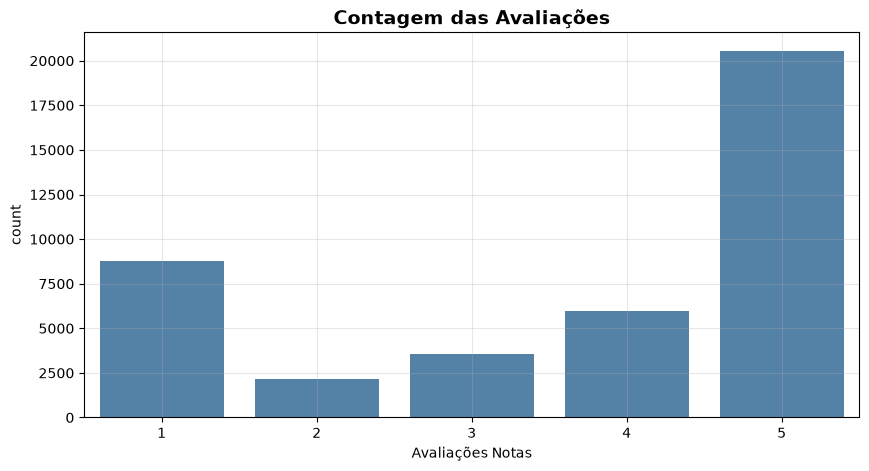

In [14]:
plt.figure(figsize=(10,5))

sns.countplot(data=df, x="nota", color="steelblue")
plt.title("Contagem das Avaliações", fontsize=14, fontweight="bold")
plt.xlabel("Avaliações Notas")
plt.grid(alpha=0.3)
plt.show()

## 7. Explorando o Vocabulário

In [15]:
all_words = " ".join(df["comentario"]).lower().split()

word_freq = Counter(all_words)

### 7.1 Palavras Frequentes Antes da Remoção de StopWords

In [16]:
top_10_words = word_freq.most_common(10)

df_top_words = pd.DataFrame(
    top_10_words, columns=["palavra", "frequencia"]
)

df_top_words

,palavra,frequencia
0,o,18676
1,e,15582
2,produto,15462
3,a,12133
4,de,11296
5,do,11139
6,não,10614
7,que,8271
8,muito,7568
9,com,5574


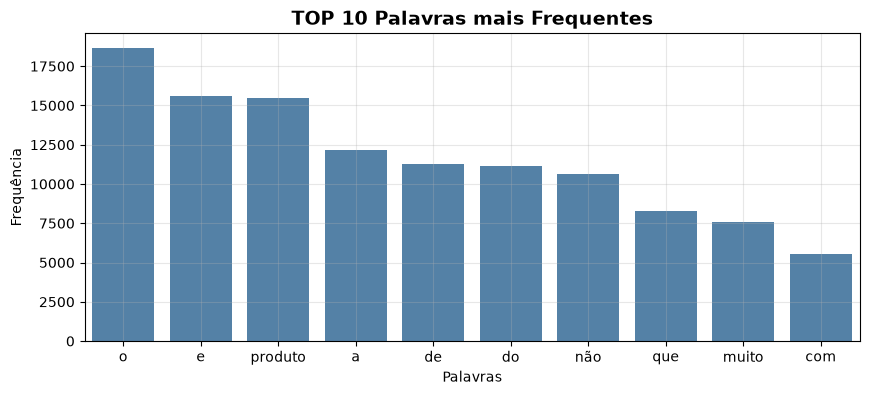

In [17]:
plt.figure(figsize=(10,4))

sns.barplot(data=df_top_words, x=df_top_words["palavra"], y=df_top_words["frequencia"], color="steelblue")
plt.title("TOP 10 Palavras mais Frequentes", fontsize=14, fontweight="bold")
plt.xlabel("Palavras")
plt.ylabel("Frequência")
plt.grid(alpha=0.3)
plt.show()

### 7.2 Palavras Frequentes Após a Remoção de StopWords

In [19]:
stop_words = set(stopwords.words("portuguese"))
negacao = {"não", "nao", "nunca", "nem", "sem"}
stop_words_pt = stop_words - negacao

filtro_words = [
    word
    for word in all_words
    if word not in stop_words_pt
]

word_freq_stop = Counter(filtro_words)

In [20]:
top_10_words_stop = word_freq_stop.most_common(10)

df_top_words_stop = pd.DataFrame(
    top_10_words_stop, columns=["palavra", "frequencia"]
)

df_top_words_stop

,palavra,frequencia
0,produto,15462
1,não,10614
2,antes,5533
3,entrega,5363
4,chegou,5130
5,prazo,5043
6,recebi,4977
7,entregue,3233
8,bom,3229
9,veio,3185


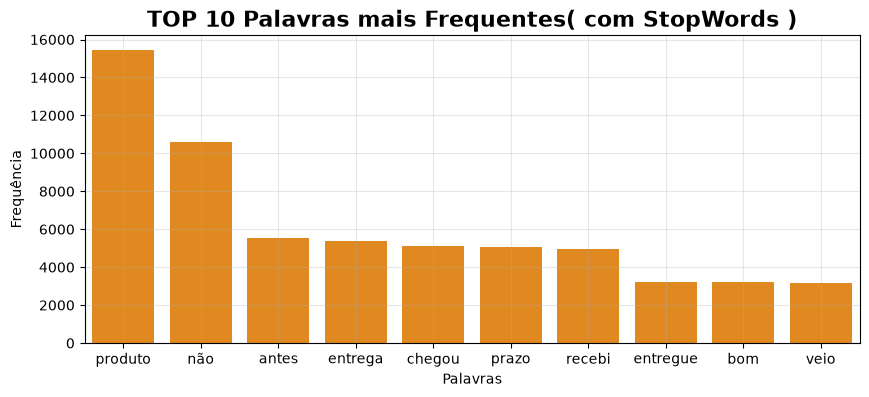

In [21]:
plt.figure(figsize=(10,4))

sns.barplot(x=df_top_words_stop["palavra"], y=df_top_words_stop["frequencia"], color="darkorange")
plt.title("TOP 10 Palavras mais Frequentes( com StopWords )", fontsize=16, fontweight="bold")
plt.xlabel("Palavras")
plt.ylabel("Frequência")
plt.grid(alpha=0.3)
plt.show()

## 8. Adicionando Feature

In [22]:
sentimento = {
    1: "negativo",
    2: "negativo",
    3: "neutro",
    4: "positivo",
    5: "positivo"
}

df["sentimento"] = df["nota"].map(sentimento)

In [23]:
df["sentimento"].value_counts().sort_index()

sentimento
negativo    10890
neutro       3557
positivo    26530
Name: count, dtype: int64

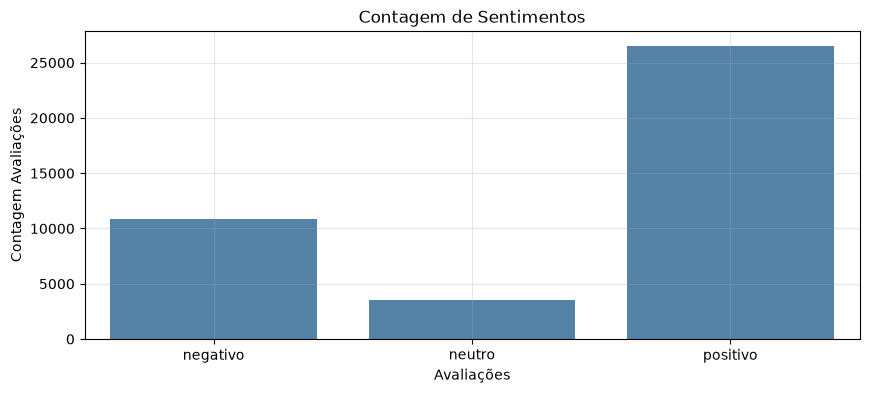

In [26]:
plt.figure(figsize=(10,4))

sns.countplot(data=df, x="sentimento", order=["negativo", "neutro", "positivo"], color="steelblue")
plt.title("Contagem de Sentimentos")
plt.xlabel("Avaliações")
plt.ylabel("Contagem Avaliações")
plt.grid(alpha=0.3)
plt.show()

## 9. Salvando Base de Dados

In [27]:
df.to_csv("../dados/processed/dados_rag.csv")

print("Dados Salvos com Sucesso!!")

Dados Salvos com Sucesso!!
